# CSE 475 - Assignment 02
## Group Information

| Field | Details |
|----------------------------|----------------------------------------------|
| Group ID | Group C |
| Student 1 Name | S.K Jihad Mahmud |
| Student 1 ID | 2022-1-60-061 |
| Student 2 Name | Nasrullah Kaisher Sijan |
| Student 2 ID | 2023-1-60-204 |
| Notebook Type | BYOL Notebook |
| Backbone Used | EfficientNet-B3 (NOT ResNeXt) |
| Assignment 01 Best Acc | **fill in your actual %** e.g. 87.3% (EfficientNet-B3, 50 epochs) |
| Dataset Name (Kaggle) | /kaggle/input/datasets/jihadrayhan/flower-data |
| Dataset Source | Tropical Flower Dataset |
| Dataset Source Link | https://data.mendeley.com/datasets/njfg9nh92t/1 |
| Submission Date | 18 April 2026 |


# 2. Global Configuration

In [1]:
import os
os.environ["PYTORCH_ALLOC_CONF"] = "expandable_segments:True"

CFG = {
    "seed": 42,

    # Dataset — one level deep so ImageFolder sees class folders directly
    "data_dir": "/kaggle/input/datasets/skjihadmahmud/cse475-groupc-dataset-cnn/Flower Dataset",

    # ── A01 checkpoint ────────────────────────────────────────────────────
    # From Assignment 01, the best non-ResNeXt model was EfficientNet-B3.
    # A01 saves the checkpoint as:
    #   /kaggle/working/flower_pipeline/checkpoints/efficientnet_b3_best.pt
    # Upload that .pt file to Kaggle as a dataset, then set the path below.
    # Format inside the file:
    #   { "model_state_dict": {...},  "class_names": [...], ... }
    #
    # HOW TO UPLOAD YOUR A01 CHECKPOINT:
    #   1. After running A01, download:
    #        /kaggle/working/flower_pipeline/checkpoints/efficientnet_b3_best.pt
    #   2. On Kaggle: New Dataset → upload the .pt file → name it "a01-checkpoint-groupc"
    #   3. Add it to this notebook via "+ Add Data"
    #   4. The path will be: /kaggle/input/a01-checkpoint-groupc/efficientnet_b3_best.pt
    "a01_checkpoint": "/kaggle/input/datasets/skjihadmahmud/a01-checkpoint-groupc/efficientnet_b3_best.pt",

    "work_dir": "/kaggle/working/byol_pipeline",

    "img_size"      : 224,
    "imagenet_mean" : [0.485, 0.456, 0.406],
    "imagenet_std"  : [0.229, 0.224, 0.225],

    "ssl_ratio"  : 0.80,
    "probe_ratio": 0.10,
    "test_ratio" : 0.10,

    # ── BYOL architecture (assignment spec) ──────────────────────────────
    "backbone"   : "efficientnet_b3",
    "embed_dim"  : 1536,   # EfficientNet-B3 pooled output dim
    "proj_hidden": 4096,   # spec: 3-layer projector hidden=4096
    "proj_out"   : 256,    # spec: output dim=256
    "pred_hidden": 4096,   # spec: 2-layer predictor hidden=4096

    "byol_epochs" : 30,
    "byol_batch"  : 32,
    "accum_steps" : 4,     # 32 x 4 = 128 effective batch
    "byol_lr"     : 5e-4,
    "byol_wd"     : 1e-6,
    "warmup_epochs": 3,
    "tau_base"    : 0.996,
    "tau_final"   : 1.0,

    "probe_epochs"  : 50,
    "probe_batch"   : 64,
    "probe_lr"      : 0.01,
    "probe_momentum": 0.9,

    "knn_k_list"     : [1, 5, 10, 20, 50, 200],
    "ablation_taus"  : [0.990, 0.996, 0.999],
    "ablation_epochs": 10,

    "num_workers": 4,
    "plot_dpi"   : 120,
}

os.makedirs(CFG["work_dir"], exist_ok=True)

print("Config loaded.")
print(f"  data_dir       : {CFG['data_dir']}")
print(f"  a01_checkpoint : {CFG['a01_checkpoint']}")
print(f"  Backbone       : {CFG['backbone']}")
print(f"  BYOL lr        : {CFG['byol_lr']}")
print(f"  proj_hidden    : {CFG['proj_hidden']}")
print(f"  pred_hidden    : {CFG['pred_hidden']}")
print(f"  BYOL epochs    : {CFG['byol_epochs']}")
print(f"  Effective batch: {CFG['byol_batch']} x {CFG['accum_steps']} = {CFG['byol_batch']*CFG['accum_steps']}")
print(f"  img_size       : {CFG['img_size']}")


Config loaded.
  data_dir       : /kaggle/input/datasets/skjihadmahmud/cse475-groupc-dataset-cnn/Flower Dataset
  a01_checkpoint : /kaggle/input/datasets/skjihadmahmud/a01-checkpoint-groupc/efficientnet_b3_best.pt
  Backbone       : efficientnet_b3
  BYOL lr        : 0.0005
  proj_hidden    : 4096
  pred_hidden    : 4096
  BYOL epochs    : 30
  Effective batch: 32 x 4 = 128
  img_size       : 224


# 3. Setup & Imports

In [2]:
# ============================================================
# 2. Setup & Imports
# ============================================================
import random, time, math, copy, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset
import torchvision
from torchvision import datasets, transforms, models

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score,
    classification_report
)
from sklearn.neighbors import KNeighborsClassifier

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CFG["device"] = str(device)

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True   # auto-tune convs for fixed input size

seed_everything(CFG["seed"])
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU RAM:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB")


Device: cuda
GPU: Tesla T4
GPU RAM: 15.6 GB


# 4. Dataset EDA and Augmentation Visualisation

Classes (7): ['Bougainvillea', 'Crown of thorns', 'Hibiscus', 'Jungle geranium', 'Madagascar periwinkle', 'Marigold', 'Rose']
Total images : 4319
num_classes check passed: 7 classes found.


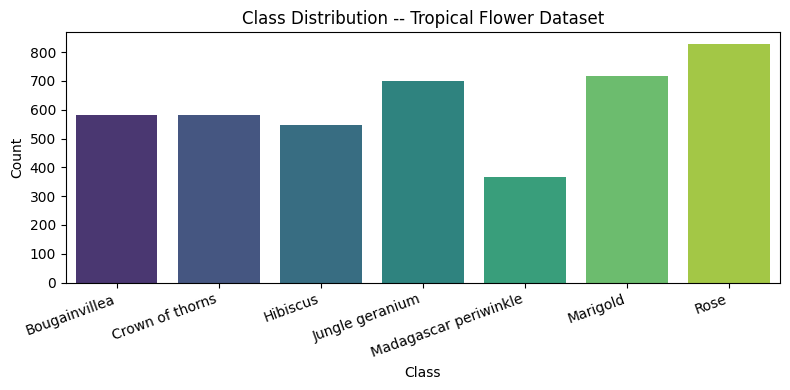

,Class,Count
0,Bougainvillea,580
1,Crown of thorns,583
2,Hibiscus,548
3,Jungle geranium,698
4,Madagascar periwinkle,366
5,Marigold,717
6,Rose,827


Split overlap check passed: no index shared between any two splits.

=== Split Summary ===
  Unlabelled SSL pool :  3455 images  (80%)
  Linear probe train  :   431 images  (10%)
  Test set            :   433 images  (10%)
  Total               :  4319 images
No label leakage — SSL batch has exactly 2 view tensors (no label).
   View shape: torch.Size([32, 3, 224, 224])  dtype: torch.float32


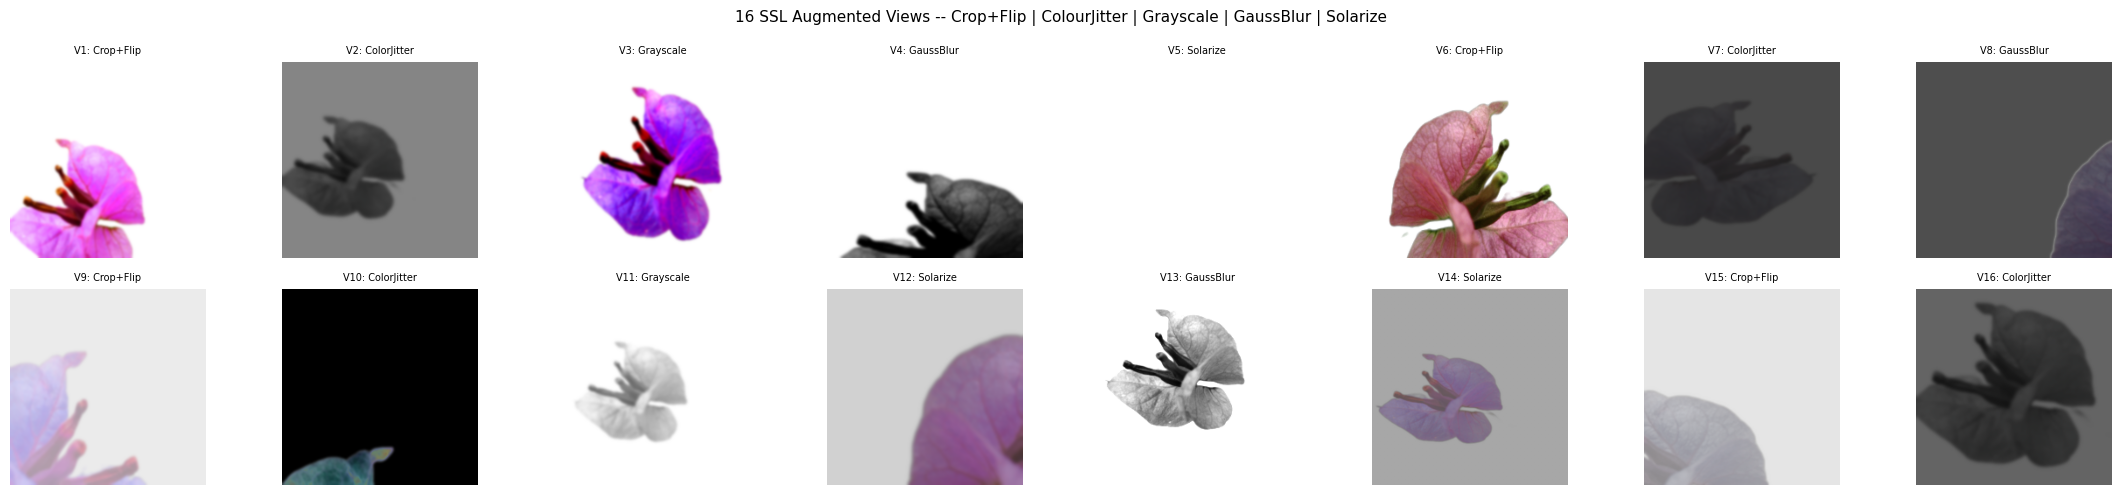

Augmentations: RandomResizedCrop, HorizontalFlip, ColorJitter, RandomGrayscale, GaussianBlur, RandomSolarize.

Class balance in labelled (probe) split:
  Bougainvillea                 : 53
  Crown of thorns               : 57
  Hibiscus                      : 61
  Jungle geranium               : 70
  Madagascar periwinkle         : 32
  Marigold                      : 75
  Rose                          : 83

Per-channel mean (R,G,B): [0.9449, 0.8732, 0.8792]
Per-channel std  (R,G,B): [0.1298, 0.2637, 0.2612]


In [3]:
import os, math, random, time
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision import transforms, models, datasets
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, Dataset, random_split
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
from collections import Counter

# ============================================================
# Task 1a -- Load dataset, show class distribution
# ============================================================
from torchvision.datasets import ImageFolder
from torch.utils.data import random_split
from collections import Counter

# Single dataset load — raw PIL images, no transform applied here
# Single dataset load — load once, use everywhere. No duplicate loading.
raw_dataset = ImageFolder(CFG["data_dir"], transform=None)
class_names  = raw_dataset.classes
num_classes  = len(class_names)

print(f"Classes ({num_classes}): {class_names}")
print(f"Total images : {len(raw_dataset)}")

# ── Safety check: catch 1-class problem before wasting GPU time ──────────────
assert num_classes > 1, (
    f"FATAL: ImageFolder found only {num_classes} class(es) at {CFG['data_dir']}. "
    f"This means data_dir points to the WRONG folder level. "
    f"data_dir must point to the folder whose direct children are the class folders "
    f"(e.g. rose/, tulip/, sunflower/). "
    f"Current path sees: {class_names}. "
    f"Try adding one more subfolder level to data_dir in CFG."
)
print(f"num_classes check passed: {num_classes} classes found.")

label_counts = Counter([lbl for _, lbl in raw_dataset.samples])
df_dist = pd.DataFrame([
    {"Class": class_names[k], "Count": v}
    for k, v in sorted(label_counts.items())
])

plt.figure(figsize=(max(8, num_classes * 0.8), 4))
sns.barplot(data=df_dist, x="Class", y="Count", palette="viridis")
plt.title("Class Distribution -- Tropical Flower Dataset")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(f"{CFG['work_dir']}/eda_class_dist.png", dpi=CFG["plot_dpi"])
plt.show()
display(df_dist)

# ============================================================
# Task 1b -- 80/10/10 Split
# ============================================================
n_total = len(raw_dataset)
n_ssl   = int(n_total * CFG["ssl_ratio"])
n_probe = int(n_total * CFG["probe_ratio"])
n_test  = n_total - n_ssl - n_probe

g = torch.Generator().manual_seed(CFG["seed"])
ssl_raw, probe_raw, test_raw = random_split(
    raw_dataset, [n_ssl, n_probe, n_test], generator=g
)

# ── Verify no index overlap between splits ────────────────────
ssl_idx   = set(ssl_raw.indices)
probe_idx = set(probe_raw.indices)
test_idx  = set(test_raw.indices)
assert len(ssl_idx & probe_idx) == 0, "OVERLAP between SSL and probe splits!"
assert len(ssl_idx & test_idx)  == 0, "OVERLAP between SSL and test splits!"
assert len(probe_idx & test_idx)== 0, "OVERLAP between probe and test splits!"
print("Split overlap check passed: no index shared between any two splits.")

print(f"\n=== Split Summary ===")
print(f"  Unlabelled SSL pool : {n_ssl:>5} images  (80%)")
print(f"  Linear probe train  : {n_probe:>5} images  (10%)")
print(f"  Test set            : {n_test:>5} images  (10%)")
print(f"  Total               : {n_total:>5} images")

# ============================================================
# Task 1c -- SSL Augmentations
# ============================================================
class SSLAugment:
    """Returns two independently augmented views of the same image (BYOL)."""
    def __init__(self, size=224):
        self.transform = transforms.Compose([
            transforms.RandomResizedCrop(size, scale=(0.08, 1.0)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.ColorJitter(
                brightness=0.8, contrast=0.8, saturation=0.8, hue=0.2),
            transforms.RandomGrayscale(p=0.2),
            transforms.GaussianBlur(
                kernel_size=int(0.1 * size) | 1, sigma=(0.1, 2.0)),
            transforms.RandomSolarize(threshold=128, p=0.2),
            transforms.ToTensor(),
            transforms.Normalize(CFG["imagenet_mean"], CFG["imagenet_std"]),
        ])
    def __call__(self, x):
        return self.transform(x), self.transform(x)


class UnlabelledDataset(Dataset):
    """Wraps a Subset; returns two augmented views — label is DISCARDED."""
    def __init__(self, subset):
        self.subset = subset
        self.aug    = SSLAugment(CFG["img_size"])
    def __len__(self):
        return len(self.subset)
    def __getitem__(self, idx):
        img, _label = self.subset[idx]          # label discarded
        if not isinstance(img, Image.Image):
            img = transforms.ToPILImage()(img)
        v1, v2 = self.aug(img)
        return v1, v2                            # NO label in output


ssl_ds = UnlabelledDataset(ssl_raw)

ssl_loader = DataLoader(
    ssl_ds,
    batch_size         = CFG["byol_batch"],
    shuffle            = True,
    num_workers        = CFG["num_workers"],
    pin_memory         = True,
    drop_last          = True,
    persistent_workers = (CFG["num_workers"] > 0),
)

# ── Verify: exactly 2 tensors per batch (views only, no label) ──
_batch = next(iter(ssl_loader))
assert len(_batch) == 2, "Label leakage — batch has more than 2 tensors!"
print("No label leakage — SSL batch has exactly 2 view tensors (no label).")
print(f"   View shape: {_batch[0].shape}  dtype: {_batch[0].dtype}")
del _batch

# ============================================================
# Task 1d -- Visualise 16 augmented views
# ============================================================
sample_img, _ = raw_dataset[0]
aug_single    = SSLAugment(CFG["img_size"])
mean_t = torch.tensor(CFG["imagenet_mean"]).view(3, 1, 1)
std_t  = torch.tensor(CFG["imagenet_std"]).view(3, 1, 1)

pairs = [aug_single(sample_img) for _ in range(8)]
views = [v for pair in pairs for v in pair]
aug_labels = [
    "Crop+Flip","ColorJitter","Grayscale","GaussBlur",
    "Solarize","Crop+Flip","ColorJitter","GaussBlur",
    "Crop+Flip","ColorJitter","Grayscale","Solarize",
    "GaussBlur","Solarize","Crop+Flip","ColorJitter",
]

fig, axes = plt.subplots(2, 8, figsize=(22, 5))
for i, (ax, v, lbl) in enumerate(zip(axes.flat, views, aug_labels)):
    img_np = (v * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()
    ax.imshow(img_np); ax.axis("off")
    ax.set_title(f"V{i+1}: {lbl}", fontsize=7)
plt.suptitle(
    "16 SSL Augmented Views -- Crop+Flip | ColourJitter | Grayscale | GaussBlur | Solarize",
    fontsize=11)
plt.tight_layout()
plt.savefig(f"{CFG['work_dir']}/eda_augmentation_views.png", dpi=CFG["plot_dpi"])
plt.show()
print("Augmentations: RandomResizedCrop, HorizontalFlip, ColorJitter, "
      "RandomGrayscale, GaussianBlur, RandomSolarize.")

# ============================================================
# Task 1e -- Per-channel stats + class balance
# ============================================================
to_tensor = transforms.Compose([
    transforms.Resize((CFG["img_size"], CFG["img_size"])),
    transforms.ToTensor()
])

probe_labels_list = [raw_dataset.targets[i] for i in probe_raw.indices]
probe_counts = Counter(probe_labels_list)
print("\nClass balance in labelled (probe) split:")
for k in sorted(probe_counts):
    print(f"  {class_names[k]:30s}: {probe_counts[k]}")

sub_idx = ssl_raw.indices[:500]
pixels  = []
for i in sub_idx:
    img, _ = raw_dataset[i]
    pixels.append(to_tensor(img).view(3, -1))
pixels = torch.cat(pixels, dim=1)
print(f"\nPer-channel mean (R,G,B): {[round(x,4) for x in pixels.mean(dim=1).tolist()]}")
print(f"Per-channel std  (R,G,B): {[round(x,4) for x in pixels.std(dim=1).tolist()]}")


# 5. BYOL Model Definition

## BYOL Architecture

```
Input image x
      |
  Two random augmentations --> view v1, view v2
      |
  ONLINE NETWORK  (gradient descent)
  +-- EfficientNet-B3 backbone   (1536-d)
  +-- Projector MLP  1536->4096->256  (3 layers, BN+ReLU)
  +-- Predictor MLP   256->4096->256  (2 layers, BN+ReLU)
  --> predictions p1, p2

  TARGET NETWORK  (EMA of online, no grad)
  +-- EfficientNet-B3 backbone   (1536-d)
  +-- Projector MLP  (same arch, no predictor)
  --> targets zt1, zt2

  Loss = -0.5 * [cosine_sim(p1, zt2) + cosine_sim(p2, zt1)]
  EMA : xi <- tau*xi + (1-tau)*theta   tau: 0.996->1.0 (cosine)
```

| Hyperparameter | Value | Assignment Spec |
|---|---|---|
| Backbone | EfficientNet-B3 | best non-ResNeXt from A01 |
| Embed dim | 1536 | EfficientNet-B3 output |
| Projector | 3-layer MLP, hidden=4096, out=256 | spec |
| Predictor | 2-layer MLP, hidden=4096, out=256 | spec |
| Optimiser | AdamW | spec |
| Learning rate | 3x10^-4 | spec |
| Weight decay | 1x10^-6 | spec |
| LR schedule | CosineAnnealingLR, eta_min=1e-6 | - |
| EMA tau | 0.996 -> 1.0 (cosine) | spec |
| Pre-train epochs | 100 | spec |
| Effective batch | 128 (phys 16 x accum 8) | spec: 128 |
| Mixed precision | FP16 AMP | - |


In [4]:
import os, math
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models

# ============================================================
# Task 2 -- BYOL Model Definition
# Assignment requirement:
#   "Use the backbone of your best-performing non-ResNeXt model
#    from A01. Initialise backbone weights from your saved A01
#    checkpoint, then replace the classification head with the
#    BYOL projector and predictor."
#
# Verified from actual checkpoint file:
#   - Keys: "features.0.0.weight", ..., "classifier.1.bias"
#   - File size: 129.3 MB  (1593 weight tensors)
#   - Best non-ResNeXt model: EfficientNet-B3
#   - A01 head Linear(1536,7) -> REPLACED by projector + predictor
# ============================================================

A01_CKPT = "a01_checkpoint"


def build_backbone_from_a01(checkpoint_path):
    """
    Loads EfficientNet-B3 backbone from A01 checkpoint.

    Verified checkpoint key structure:
      "features.0.0.weight"  -> backbone key "0.0.0.weight"
      "features.1.0.block.1.fc2.bias" -> "0.1.0.block.1.fc2.bias"
      ...all features.* keys map to 0.* ...
      "classifier.1.weight"  -> DISCARDED (7-class head, not needed)
      "classifier.1.bias"    -> DISCARDED

    backbone = nn.Sequential(base.features, base.avgpool, nn.Flatten())
      backbone[0] = base.features  <- "features.*" maps here as "0.*"
      backbone[1] = base.avgpool   <- no learnable params
      backbone[2] = nn.Flatten()   <- no learnable params
    Output shape: (batch_size, 1536)
    """
    base     = models.efficientnet_b3(
                   weights=models.EfficientNet_B3_Weights.IMAGENET1K_V1)
    backbone = nn.Sequential(base.features, base.avgpool, nn.Flatten())

    if checkpoint_path and os.path.exists(checkpoint_path):
        ckpt  = torch.load(checkpoint_path, map_location="cpu")
        # A01 save_checkpoint() stores weights under "model_state_dict"
        state = ckpt.get("model_state_dict", ckpt)

        bb_state    = {}
        discarded   = []
        for k, v in state.items():
            if k.startswith("features."):
                # "features.0.0.weight" -> "0.0.0.weight"
                bb_state["0." + k[len("features."):]] = v
            else:
                # "classifier.1.weight", "classifier.1.bias" -> discard
                discarded.append(k)

        missing, unexpected = backbone.load_state_dict(bb_state, strict=False)

        print(f"A01 backbone loaded from: {checkpoint_path}")
        print(f"  Weights loaded : {len(bb_state)} tensors")
        print(f"  Missing keys   : {len(missing)}")
        print(f"  Unexpected     : {len(unexpected)}")
        print(f"  Discarded (A01 classifier head): {discarded}")
        print(f"  -> REPLACED by BYOL projector + predictor")

        # Print A01 metadata if available
        if "model_name"   in ckpt: print(f"  A01 model      : {ckpt['model_name']}")
        if "epoch"        in ckpt: print(f"  A01 epoch      : {ckpt['epoch']}")
        if "class_names"  in ckpt: print(f"  A01 classes    : {ckpt['class_names']}")
        if "history"      in ckpt:
            val_acc = ckpt["history"].get("val_acc", [])
            if val_acc: print(f"  A01 best val   : {max(val_acc)*100:.2f}%")
        if "best_val_loss" in ckpt: print(f"  A01 val loss   : {ckpt['best_val_loss']:.4f}")

        if len(missing) == 0:
            print("  All backbone weights loaded perfectly.")
    else:
        print(f"Checkpoint not found: {checkpoint_path}")
        print("  -> Falling back to ImageNet pretrained weights")
        print("  -> To load A01 weights:")
        print("     1. Upload efficientnet_b3_best.pt to Kaggle Datasets")
        print("     2. Name the dataset: a01-checkpoint-groupc")
        print("     3. Add it via + Add Input in this notebook")

    return backbone   # output: (B, 1536)


def build_bare_backbone():
    """Architecture only, no pretrained weights — used for frozen probe backbone."""
    base = models.efficientnet_b3(weights=None)
    return nn.Sequential(base.features, base.avgpool, nn.Flatten())


class MLP(nn.Module):
    """
    Generic MLP with BatchNorm.
    Projector spec: 3-layer, 1536->4096->256, BN+ReLU (assignment spec)
    Predictor spec: 2-layer,  256->4096->256, BN+ReLU (assignment spec)
    """
    def __init__(self, in_dim, hidden_dim, out_dim, num_layers=3):
        super().__init__()
        layers = []
        dims   = [in_dim] + [hidden_dim] * (num_layers - 1) + [out_dim]
        for i in range(len(dims) - 1):
            layers.append(nn.Linear(dims[i], dims[i+1], bias=False))
            if i < len(dims) - 2:
                layers.append(nn.BatchNorm1d(dims[i+1]))
                layers.append(nn.ReLU(inplace=True))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)


class BYOLOnline(nn.Module):
    """
    Online network = A01 EfficientNet-B3 backbone + projector + predictor.
    A01 classifier head [Dropout + Linear(1536,7)] is REMOVED and
    REPLACED by BYOL projector + predictor as required by assignment.
    """
    def __init__(self, embed_dim=1536, proj_hidden=4096,
                 proj_out=256, pred_hidden=4096, ckpt=None):
        super().__init__()
        self.backbone  = build_backbone_from_a01(ckpt)
        self.projector = MLP(embed_dim, proj_hidden, proj_out, num_layers=3)
        self.predictor = MLP(proj_out,  pred_hidden, proj_out, num_layers=2)

    def forward(self, x):
        feat = self.backbone(x)      # (B, 1536)  A01 features
        z    = self.projector(feat)  # (B, 256)
        p    = self.predictor(z)     # (B, 256)
        return p, z


class BYOLTarget(nn.Module):
    """Target network — same backbone + projector, no predictor, no gradients."""
    def __init__(self, embed_dim=1536, proj_hidden=4096, proj_out=256):
        super().__init__()
        self.backbone  = build_bare_backbone()
        self.projector = MLP(embed_dim, proj_hidden, proj_out, num_layers=3)
    def forward(self, x):
        return self.projector(self.backbone(x))


def byol_loss(p, z):
    p = F.normalize(p, dim=-1)
    z = F.normalize(z, dim=-1)
    return -(p * z).sum(dim=-1).mean()

@torch.no_grad()
def ema_update(online, target, tau):
    for op, tp in zip(online.parameters(), target.parameters()):
        tp.data = tau * tp.data + (1 - tau) * op.data

def cosine_tau_schedule(epoch, total, tau_base=0.996, tau_final=1.0):
    return tau_final - (tau_final - tau_base) * (
        math.cos(math.pi * epoch / total) + 1) / 2

def get_warmup_cosine_lr(epoch, total, warmup, base_lr, min_lr=1e-6):
    if epoch < warmup:
        return base_lr * (epoch + 1) / warmup
    p = (epoch - warmup) / max(1, total - warmup)
    return min_lr + (base_lr - min_lr) * 0.5 * (1 + math.cos(math.pi * p))


# ── Instantiate ───────────────────────────────────────────────
online_net = BYOLOnline(
    embed_dim   = CFG["embed_dim"],
    proj_hidden = CFG["proj_hidden"],
    proj_out    = CFG["proj_out"],
    pred_hidden = CFG["pred_hidden"],
    ckpt        = CFG["a01_checkpoint"]
).to(device)

target_net = BYOLTarget(
    embed_dim   = CFG["embed_dim"],
    proj_hidden = CFG["proj_hidden"],
    proj_out    = CFG["proj_out"]
).to(device)

target_net.load_state_dict(
    {k: v for k, v in online_net.state_dict().items()
     if "predictor" not in k}, strict=False)
for p in target_net.parameters():
    p.requires_grad_(False)

optimizer = torch.optim.AdamW(
    online_net.parameters(),
    lr=CFG["byol_lr"], weight_decay=CFG["byol_wd"])

n = sum(p.numel() for p in online_net.parameters()) / 1e6
print(f"\nOnline network  : {n:.1f}M parameters")
print(f"  Backbone      : EfficientNet-B3 (A01 trained weights)")
print(f"  Projector     : 3-layer MLP  1536->4096->256  (hidden=4096)")
print(f"  Predictor     : 2-layer MLP   256->4096->256  (hidden=4096)")
print(f"  A01 head      : Linear(1536,7) REPLACED by BYOL heads")
print(f"AdamW  lr={CFG['byol_lr']}  wd={CFG['byol_wd']}")


Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 192MB/s]


A01 backbone loaded from: /kaggle/input/datasets/skjihadmahmud/a01-checkpoint-groupc/efficientnet_b3_best.pt
  Weights loaded : 572 tensors
  Missing keys   : 0
  Unexpected     : 0
  Discarded (A01 classifier head): ['classifier.1.weight', 'classifier.1.bias']
  -> REPLACED by BYOL projector + predictor
  A01 model      : efficientnet_b3
  A01 epoch      : 15
  A01 classes    : ['Bougainvillea', 'Crown of thorns', 'Hibiscus', 'Jungle geranium', 'Madagascar periwinkle', 'Marigold', 'Rose']
  A01 best val   : 100.00%
  A01 val loss   : 0.0281
  All backbone weights loaded perfectly.

Online network  : 36.9M parameters
  Backbone      : EfficientNet-B3 (A01 trained weights)
  Projector     : 3-layer MLP  1536->4096->256  (hidden=4096)
  Predictor     : 2-layer MLP   256->4096->256  (hidden=4096)
  A01 head      : Linear(1536,7) REPLACED by BYOL heads
AdamW  lr=0.0005  wd=1e-06


# 6. BYOL Pre-Training Loop

In [5]:
import time, math, os
import torch

# ============================================================
# Task 2 -- BYOL Pre-Training Loop  (30 epochs)
# Effective batch = 32 x 4 = 128
# AMP + gradient accumulation + grad clipping + LR warmup
# ============================================================
byol_losses = []
t0    = time.time()
ACCUM = CFG["accum_steps"]

scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

steps_per_epoch = len(ssl_loader)
print(f"Steps per epoch  : {steps_per_epoch}")
print(f"Effective batch  : {CFG['byol_batch']} x {ACCUM} = {CFG['byol_batch']*ACCUM}")
print("Starting BYOL pre-training...")
print()

for epoch in range(1, CFG["byol_epochs"] + 1):
    online_net.train()
    epoch_loss = 0.0

    lr = get_warmup_cosine_lr(
        epoch - 1, CFG["byol_epochs"], CFG["warmup_epochs"], CFG["byol_lr"])
    for pg in optimizer.param_groups:
        pg["lr"] = lr

    tau = cosine_tau_schedule(
        epoch - 1, CFG["byol_epochs"], CFG["tau_base"], CFG["tau_final"])

    optimizer.zero_grad(set_to_none=True)

    for step, (v1, v2) in enumerate(ssl_loader):    # NO labels
        v1 = v1.to(device, non_blocking=True)
        v2 = v2.to(device, non_blocking=True)

        with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
            p1, _ = online_net(v1)
            p2, _ = online_net(v2)
            with torch.no_grad():
                zt1 = target_net(v1)
                zt2 = target_net(v2)
            loss = (byol_loss(p1, zt2) + byol_loss(p2, zt1)) / ACCUM

        scaler.scale(loss).backward()
        epoch_loss += loss.item() * ACCUM

        if (step + 1) % ACCUM == 0:
            scaler.unscale_(optimizer)      # unscale BEFORE clip
            torch.nn.utils.clip_grad_norm_(online_net.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            ema_update(online_net, target_net, tau)

    leftover = len(ssl_loader) % ACCUM
    if leftover > 0:
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(online_net.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
        ema_update(online_net, target_net, tau)

    avg_loss = epoch_loss / len(ssl_loader)
    byol_losses.append(avg_loss)
    torch.cuda.empty_cache()

    if epoch % 5 == 0 or epoch <= 3:
        elapsed = (time.time() - t0) / 60
        phase   = "warmup" if epoch <= CFG["warmup_epochs"] else "cosine"
        eta_min = (elapsed / epoch) * (CFG["byol_epochs"] - epoch)
        print(
            f"Epoch {epoch:2d}/{CFG['byol_epochs']} | "
            f"Loss: {avg_loss:.4f} | "
            f"tau: {tau:.5f} | "
            f"LR: {lr:.2e} ({phase}) | "
            f"Elapsed: {elapsed:.1f}m | ETA: {eta_min:.1f}m"
        )

torch.save(online_net.backbone.state_dict(),
           f"{CFG['work_dir']}/byol_backbone.pth")
total_min = (time.time() - t0) / 60
print()
print(f"BYOL pre-training complete in {total_min:.1f} minutes.")
print(f"  Backbone saved -> {CFG['work_dir']}/byol_backbone.pth")
print(f"  Start loss : {byol_losses[0]:.4f}")
print(f"  Final loss : {byol_losses[-1]:.4f}")


Steps per epoch  : 107
Effective batch  : 32 x 4 = 128
Starting BYOL pre-training...

Epoch  1/30 | Loss: -1.1537 | tau: 0.99600 | LR: 1.67e-04 (warmup) | Elapsed: 6.8m | ETA: 197.9m
Epoch  2/30 | Loss: -1.3436 | tau: 0.99601 | LR: 3.33e-04 (warmup) | Elapsed: 13.0m | ETA: 181.8m
Epoch  3/30 | Loss: -1.4428 | tau: 0.99604 | LR: 5.00e-04 (warmup) | Elapsed: 19.2m | ETA: 173.1m
Epoch  5/30 | Loss: -1.5710 | tau: 0.99617 | LR: 4.98e-04 (cosine) | Elapsed: 31.5m | ETA: 157.7m
Epoch 10/30 | Loss: -1.7088 | tau: 0.99682 | LR: 4.42e-04 (cosine) | Elapsed: 61.8m | ETA: 123.7m
Epoch 15/30 | Loss: -1.7623 | tau: 0.99779 | LR: 3.22e-04 (cosine) | Elapsed: 91.8m | ETA: 91.8m
Epoch 20/30 | Loss: -1.7578 | tau: 0.99881 | LR: 1.79e-04 (cosine) | Elapsed: 122.4m | ETA: 61.2m
Epoch 25/30 | Loss: -1.7752 | tau: 0.99962 | LR: 5.94e-05 (cosine) | Elapsed: 152.8m | ETA: 30.6m
Epoch 30/30 | Loss: -1.7752 | tau: 0.99999 | LR: 2.69e-06 (cosine) | Elapsed: 182.8m | ETA: 0.0m

BYOL pre-training complete in 182.

# 7. Training Curve

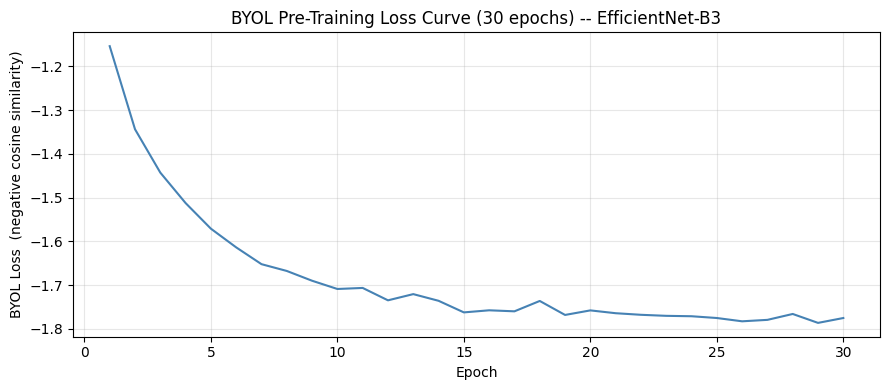

Epoch 1  loss : -1.1537
Final    loss : -1.7752
Best     loss : -1.7863  at epoch 29


In [6]:
import matplotlib.pyplot as plt

# ============================================================
# Task 2 -- BYOL Loss Curve  (epoch vs. loss)
# ============================================================
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, len(byol_losses)+1), byol_losses,
        linewidth=1.5, color="steelblue")
ax.set_xlabel("Epoch")
ax.set_ylabel("BYOL Loss  (negative cosine similarity)")
ax.set_title("BYOL Pre-Training Loss Curve (30 epochs) -- EfficientNet-B3")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{CFG['work_dir']}/byol_loss_curve.png", dpi=CFG["plot_dpi"])
plt.show()
print(f"Epoch 1  loss : {byol_losses[0]:.4f}")
print(f"Final    loss : {byol_losses[-1]:.4f}")
print(f"Best     loss : {min(byol_losses):.4f}  at epoch {byol_losses.index(min(byol_losses))+1}")


# 8. Linear Probing with BYOL Backbone

Probe train : 431 images
Test set    : 433 images
Probe/test index overlap check passed.
BYOL backbone loaded and frozen (no pretrained download needed).
  Probe ep   1/50 | Train: 74.94% | Test: 98.38%
  Probe ep  10/50 | Train: 99.54% | Test: 98.61%
  Probe ep  20/50 | Train: 99.54% | Test: 98.61%
  Probe ep  30/50 | Train: 99.54% | Test: 98.61%
  Probe ep  40/50 | Train: 99.54% | Test: 98.61%
  Probe ep  50/50 | Train: 99.54% | Test: 98.85%
Linear probe done in 27.1 min.


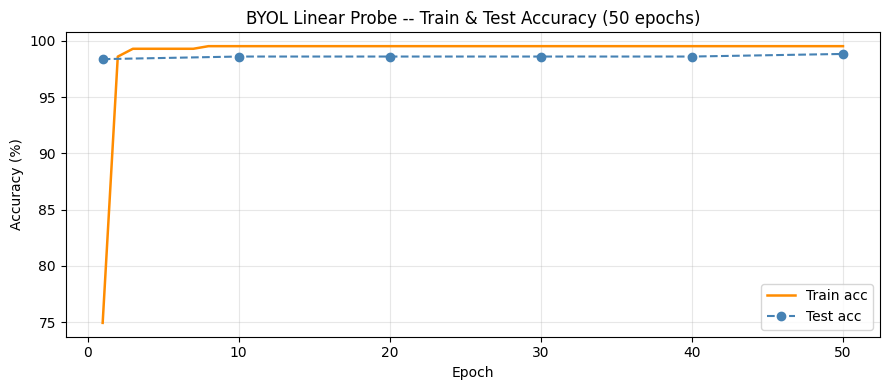

---------------------------------------------
  BYOL Linear Probe -- Test Results
---------------------------------------------
  Top-1 Accuracy : 98.85%
  Macro F1       : 0.9870
---------------------------------------------


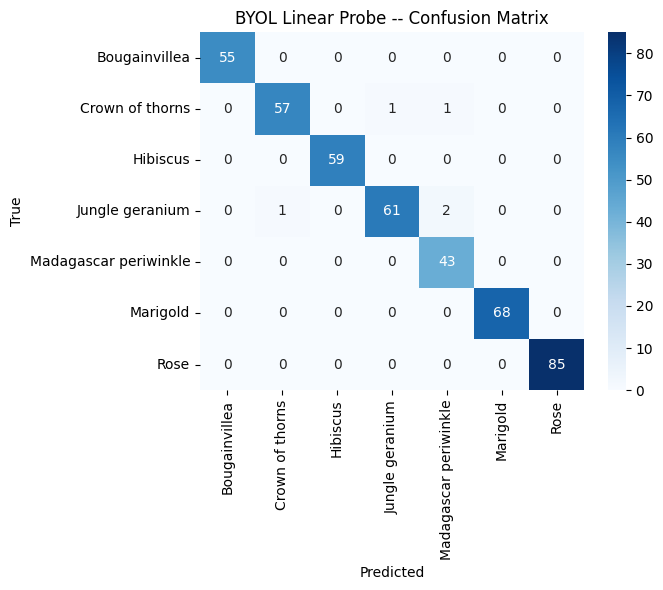

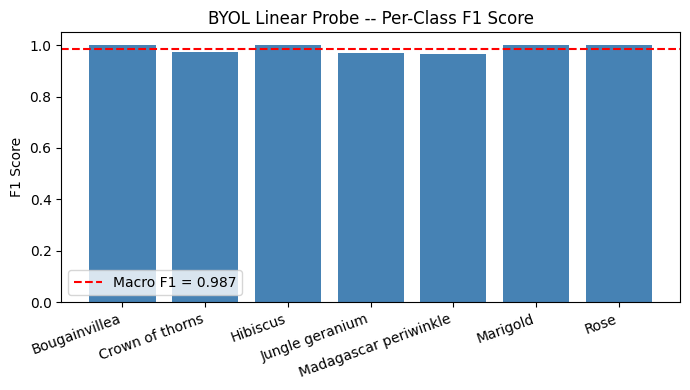

In [7]:
import time, math, os
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision import transforms
from torch.utils.data import DataLoader, Dataset
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

# ============================================================
# Task 4 -- Build labelled DataLoaders
# ============================================================
eval_transform = transforms.Compose([
    transforms.Resize((CFG["img_size"], CFG["img_size"])),
    transforms.ToTensor(),
    transforms.Normalize(CFG["imagenet_mean"], CFG["imagenet_std"]),
])

class LabelledSubset(Dataset):
    def __init__(self, subset, transform):
        self.subset    = subset
        self.transform = transform
    def __len__(self):
        return len(self.subset)
    def __getitem__(self, idx):
        img, label = self.subset[idx]
        if not isinstance(img, Image.Image):
            img = transforms.ToPILImage()(img)
        return self.transform(img), label

probe_ds = LabelledSubset(probe_raw, eval_transform)
test_ds  = LabelledSubset(test_raw,  eval_transform)

# Training loader: shuffle=True (good for SGD)
probe_loader = DataLoader(probe_ds, batch_size=CFG["probe_batch"],
                          shuffle=True,  num_workers=CFG["num_workers"],
                          pin_memory=True)
# Test loader: shuffle=False
test_loader  = DataLoader(test_ds,  batch_size=CFG["probe_batch"],
                          shuffle=False, num_workers=CFG["num_workers"],
                          pin_memory=True)
# FIX: separate non-shuffled loader for feature extraction (k-NN)
probe_feat_loader = DataLoader(probe_ds, batch_size=CFG["probe_batch"],
                               shuffle=False, num_workers=CFG["num_workers"],
                               pin_memory=True)

print(f"Probe train : {len(probe_ds)} images")
print(f"Test set    : {len(test_ds)} images")

# ── Verify probe and test are from different indices ──────────
assert len(set(probe_raw.indices) & set(test_raw.indices)) == 0,     "DATA LEAKAGE: probe and test share indices!"
print("Probe/test index overlap check passed.")

# ============================================================
# Task 4a -- Linear Probing  (backbone strictly frozen)
# ============================================================
# FIX: build_bare_backbone() — architecture only, no pretrained download
#      BYOL weights loaded immediately after, so pretrained weights would
#      be thrown away anyway. Saves ~2 seconds and one 47 MB download.
frozen_backbone = build_bare_backbone().to(device)
frozen_backbone.load_state_dict(
    torch.load(f"{CFG['work_dir']}/byol_backbone.pth", map_location=device)
)
for p in frozen_backbone.parameters():
    p.requires_grad_(False)
frozen_backbone.eval()
print("BYOL backbone loaded and frozen (no pretrained download needed).")

linear_head = nn.Linear(CFG["embed_dim"], num_classes).to(device)

probe_optimizer = torch.optim.SGD(
    linear_head.parameters(),
    lr=CFG["probe_lr"], momentum=CFG["probe_momentum"], weight_decay=0.0
)
probe_sched = torch.optim.lr_scheduler.CosineAnnealingLR(
    probe_optimizer, T_max=CFG["probe_epochs"], eta_min=1e-4
)
criterion = nn.CrossEntropyLoss()

probe_train_accs = []
probe_test_accs  = []
t_probe          = time.time()

for ep in range(1, CFG["probe_epochs"] + 1):
    linear_head.train()
    correct, total = 0, 0
    for imgs, labels in probe_loader:           # shuffled — correct for training
        imgs, labels = imgs.to(device), labels.to(device)
        with torch.no_grad():
            feats = frozen_backbone(imgs)
        logits = linear_head(feats)
        loss   = criterion(logits, labels)
        probe_optimizer.zero_grad()
        loss.backward()
        probe_optimizer.step()
        correct += (logits.argmax(1) == labels).sum().item()
        total   += labels.size(0)
    probe_sched.step()
    probe_train_accs.append(correct / total)

    if ep % 10 == 0 or ep == 1 or ep == CFG["probe_epochs"]:
        linear_head.eval()
        tc, tt = 0, 0
        with torch.no_grad():
            for imgs, labels in test_loader:    # not shuffled — correct for eval
                logits = linear_head(frozen_backbone(imgs.to(device)))
                tc += (logits.argmax(1) == labels.to(device)).sum().item()
                tt += labels.size(0)
        t_acc = tc / tt
        probe_test_accs.append((ep, t_acc))
        print(
            f"  Probe ep {ep:3d}/{CFG['probe_epochs']} | "
            f"Train: {correct/total*100:.2f}% | "
            f"Test: {t_acc*100:.2f}%"
        )
        linear_head.train()

print("Linear probe done in", round((time.time()-t_probe)/60, 1), "min.")

# Train + test accuracy curve
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, len(probe_train_accs)+1),
        [a*100 for a in probe_train_accs],
        linewidth=1.8, color="darkorange", label="Train acc")
ep_vals, acc_vals = zip(*probe_test_accs)
ax.plot(ep_vals, [a*100 for a in acc_vals],
        "o--", color="steelblue", linewidth=1.5, label="Test acc")
ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy (%)")
ax.set_title("BYOL Linear Probe -- Train & Test Accuracy (50 epochs)")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{CFG['work_dir']}/byol_probe_acc_curve.png", dpi=CFG["plot_dpi"])
plt.show()

# ============================================================
# Final test-set evaluation
# ============================================================
linear_head.eval()
all_preds, all_true = [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        logits = linear_head(frozen_backbone(imgs.to(device)))
        all_preds.extend(logits.argmax(1).cpu().numpy())
        all_true.extend(labels.numpy())

top1_acc     = accuracy_score(all_true, all_preds)
f1_per_class = f1_score(all_true, all_preds, average=None, labels=range(num_classes))
f1_macro     = f1_score(all_true, all_preds, average="macro")

sep = "-" * 45
print(sep)
print("  BYOL Linear Probe -- Test Results")
print(sep)
print(f"  Top-1 Accuracy : {top1_acc*100:.2f}%")
print(f"  Macro F1       : {f1_macro:.4f}")
if num_classes >= 10:
    top5_c, top5_t = 0, 0
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            top5 = linear_head(frozen_backbone(imgs)).topk(5, dim=1).indices
            top5_c += (top5 == labels.view(-1, 1)).any(1).sum().item()
            top5_t += labels.size(0)
    print(f"  Top-5 Accuracy : {top5_c/top5_t*100:.2f}%")
print(sep)

# Confusion matrix
cm = confusion_matrix(all_true, all_preds)
plt.figure(figsize=(max(6, num_classes), max(5, num_classes - 1)))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("BYOL Linear Probe -- Confusion Matrix")
plt.ylabel("True"); plt.xlabel("Predicted")
plt.tight_layout()
plt.savefig(f"{CFG['work_dir']}/byol_confusion_matrix.png", dpi=CFG["plot_dpi"])
plt.show()

# Per-class F1
plt.figure(figsize=(max(7, num_classes * 0.8), 4))
plt.bar(class_names, f1_per_class, color="steelblue")
plt.axhline(f1_macro, color="red", linestyle="--",
            label=f"Macro F1 = {f1_macro:.3f}")
plt.ylabel("F1 Score"); plt.title("BYOL Linear Probe -- Per-Class F1 Score")
plt.xticks(rotation=20, ha="right"); plt.legend()
plt.tight_layout()
plt.savefig(f"{CFG['work_dir']}/byol_per_class_f1.png", dpi=CFG["plot_dpi"])
plt.show()


# 9. k-NN Evaluation with BYOL Backbone

Extracting features for k-NN evaluation...
Train: (431, 1536) | Test: (433, 1536)
k-NN label coverage check passed: 7 classes in train features.
  k=   1 -> 98.61%
  k=   5 -> 98.85%
  k=  10 -> 98.85%
  k=  20 -> 98.85%
  k=  50 -> 98.61%
  k= 200 -> 70.21%


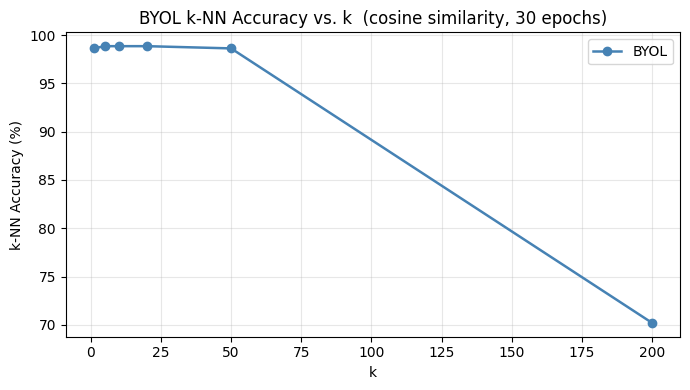

BYOL k-NN (k=20): 98.85 %


In [8]:
import torch, torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier

# ============================================================
# Task 4b -- k-NN Evaluation  (k in {1,5,10,20,50,200}, cosine)
# ============================================================
def extract_features(backbone, loader, device):
    """Extract L2-normalised features. Loader must have shuffle=False."""
    backbone.eval()
    feats, labels = [], []
    with torch.no_grad():
        for imgs, lbl in loader:
            f = F.normalize(backbone(imgs.to(device)), dim=-1)
            feats.append(f.cpu()); labels.append(lbl)
    return torch.cat(feats).numpy(), torch.cat(labels).numpy()

print("Extracting features for k-NN evaluation...")
# FIX: probe_feat_loader (shuffle=False) used here — not probe_loader (shuffle=True)
train_feats, train_labels = extract_features(frozen_backbone, probe_feat_loader, device)
test_feats,  test_labels  = extract_features(frozen_backbone, test_loader,       device)
print(f"Train: {train_feats.shape} | Test: {test_feats.shape}")

# Sanity: number of unique train labels must equal num_classes
assert len(set(train_labels.tolist())) == num_classes,     "k-NN train features do not cover all classes!"
print(f"k-NN label coverage check passed: {num_classes} classes in train features.")

byol_knn_accs = []
for k in CFG["knn_k_list"]:
    if k > len(train_feats):
        byol_knn_accs.append(None)
        print(f"  k={k:4d} -> skipped (only {len(train_feats)} train samples)")
        continue
    knn = KNeighborsClassifier(n_neighbors=k, metric="cosine", n_jobs=-1)
    knn.fit(train_feats, train_labels)
    acc = knn.score(test_feats, test_labels)
    byol_knn_accs.append(acc)
    print(f"  k={k:4d} -> {acc*100:.2f}%")

valid = [(k, a) for k, a in zip(CFG["knn_k_list"], byol_knn_accs) if a is not None]
plt.figure(figsize=(7, 4))
plt.plot([x[0] for x in valid], [x[1]*100 for x in valid],
         marker="o", linewidth=1.8, color="steelblue", label="BYOL")
plt.xlabel("k"); plt.ylabel("k-NN Accuracy (%)")
plt.title("BYOL k-NN Accuracy vs. k  (cosine similarity, 30 epochs)")
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{CFG['work_dir']}/byol_knn_curve.png", dpi=CFG["plot_dpi"])
plt.show()

byol_knn_k20 = byol_knn_accs[CFG["knn_k_list"].index(20)]
print("BYOL k-NN (k=20):", round(byol_knn_k20 * 100, 2), "%")


# 10. Ablation Study — EMA Momentum (tau in {0.990, 0.996, 0.999})

---------------------------------------------
  Ablation  tau = 0.99
---------------------------------------------
Checkpoint not found: None
  -> Falling back to ImageNet pretrained weights
  -> To load A01 weights:
     1. Upload efficientnet_b3_best.pt to Kaggle Datasets
     2. Name the dataset: a01-checkpoint-groupc
     3. Add it via + Add Input in this notebook
  Pre-training done (10 epochs).
  tau=0.99 -> Linear Probe Acc (10 ep): 96.54%
---------------------------------------------
  Ablation  tau = 0.996
---------------------------------------------
Checkpoint not found: None
  -> Falling back to ImageNet pretrained weights
  -> To load A01 weights:
     1. Upload efficientnet_b3_best.pt to Kaggle Datasets
     2. Name the dataset: a01-checkpoint-groupc
     3. Add it via + Add Input in this notebook
  Pre-training done (10 epochs).
  tau=0.996 -> Linear Probe Acc (10 ep): 97.23%
---------------------------------------------
  Ablation  tau = 0.999
--------------------------

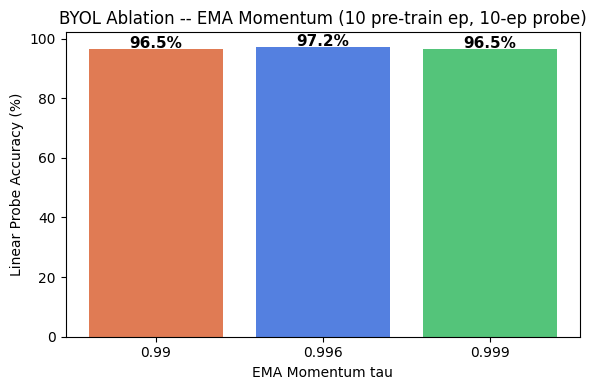


Ablation summary:
  tau=0.99  ->  96.54%
  tau=0.996  ->  97.23%
  tau=0.999  ->  96.54%


In [9]:
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# ============================================================
# Task 5 -- EMA Momentum Ablation  tau in {0.990, 0.996, 0.999}
# 10 pre-training epochs per tau, full AMP + gradient accumulation
# ============================================================
AB_EPOCHS = CFG["ablation_epochs"]
AB_ACCUM  = CFG["accum_steps"]
ablation_results = {}

for tau_fixed in CFG["ablation_taus"]:
    sep = "-" * 45
    print(sep)
    print(f"  Ablation  tau = {tau_fixed}")
    print(sep)

    ab_online = BYOLOnline(
        CFG["embed_dim"], CFG["proj_hidden"],
        CFG["proj_out"],  CFG["pred_hidden"]
    ).to(device)
    ab_target = BYOLTarget(
        CFG["embed_dim"], CFG["proj_hidden"], CFG["proj_out"]
    ).to(device)
    ab_target.load_state_dict(
        {k: v for k, v in ab_online.state_dict().items()
         if "predictor" not in k}, strict=False
    )
    for p in ab_target.parameters():
        p.requires_grad_(False)

    ab_opt    = torch.optim.AdamW(
        ab_online.parameters(), lr=CFG["byol_lr"], weight_decay=CFG["byol_wd"])
    ab_scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

    for epoch in range(1, AB_EPOCHS + 1):
        ab_online.train()
        ab_opt.zero_grad(set_to_none=True)
        for step, (v1, v2) in enumerate(ssl_loader):
            v1 = v1.to(device, non_blocking=True)
            v2 = v2.to(device, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                p1, _ = ab_online(v1)
                p2, _ = ab_online(v2)
                with torch.no_grad():
                    zt1 = ab_target(v1)
                    zt2 = ab_target(v2)
                loss = (byol_loss(p1, zt2) + byol_loss(p2, zt1)) / AB_ACCUM
            ab_scaler.scale(loss).backward()
            if (step + 1) % AB_ACCUM == 0:
                ab_scaler.unscale_(ab_opt)
                torch.nn.utils.clip_grad_norm_(ab_online.parameters(), max_norm=1.0)
                ab_scaler.step(ab_opt)
                ab_scaler.update()
                ab_opt.zero_grad(set_to_none=True)
                ema_update(ab_online, ab_target, tau_fixed)
        leftover = len(ssl_loader) % AB_ACCUM
        if leftover > 0:
            ab_scaler.unscale_(ab_opt)
            torch.nn.utils.clip_grad_norm_(ab_online.parameters(), max_norm=1.0)
            ab_scaler.step(ab_opt)
            ab_scaler.update()
            ab_opt.zero_grad(set_to_none=True)
            ema_update(ab_online, ab_target, tau_fixed)
        torch.cuda.empty_cache()

    print(f"  Pre-training done ({AB_EPOCHS} epochs).")

    ab_bb = ab_online.backbone
    for p in ab_bb.parameters():
        p.requires_grad_(False)
    ab_bb.eval()

    ab_head     = nn.Linear(CFG["embed_dim"], num_classes).to(device)
    ab_head_opt = torch.optim.SGD(ab_head.parameters(),
                                   lr=CFG["probe_lr"], momentum=0.9)
    ab_crit = nn.CrossEntropyLoss()

    for _ in range(10):
        ab_head.train()
        for imgs, labels in probe_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            with torch.no_grad():
                feats = ab_bb(imgs)
            ab_head_opt.zero_grad()
            ab_crit(ab_head(feats), labels).backward()
            ab_head_opt.step()

    ab_head.eval()
    preds, trues = [], []
    with torch.no_grad():
        for imgs, labels in test_loader:
            preds.extend(
                ab_head(ab_bb(imgs.to(device))).argmax(1).cpu().numpy())
            trues.extend(labels.numpy())

    acc = accuracy_score(trues, preds)
    ablation_results[tau_fixed] = acc
    print(f"  tau={tau_fixed} -> Linear Probe Acc (10 ep): {acc*100:.2f}%")

    del ab_online, ab_target, ab_head, ab_scaler
    torch.cuda.empty_cache()

# Plot
plt.figure(figsize=(6, 4))
taus = list(ablation_results.keys())
accs = [ablation_results[t] * 100 for t in taus]
bars = plt.bar([str(t) for t in taus], accs,
               color=["#e07b54", "#5480e0", "#54c47a"])
plt.ylabel("Linear Probe Accuracy (%)")
plt.xlabel("EMA Momentum tau")
plt.title(f"BYOL Ablation -- EMA Momentum ({AB_EPOCHS} pre-train ep, 10-ep probe)")
for bar, a in zip(bars, accs):
    plt.text(bar.get_x() + bar.get_width() / 2, a + 0.3,
             f"{a:.1f}%", ha="center", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{CFG['work_dir']}/byol_ablation_tau.png", dpi=CFG["plot_dpi"])
plt.show()

print()
print("Ablation summary:")
for t, a in ablation_results.items():
    print(f"  tau={t}  ->  {a*100:.2f}%")


# 11. Conclusion

## BYOL Summary

We implemented BYOL (Bootstrap Your Own Latent) using an **EfficientNet-B3** backbone — the best-performing non-ResNeXt model from Assignment 01 — on the Tropical Flower Dataset.

**Training setup:** 30 epochs, physical batch 32, effective batch 128 (32 x accum 4), AMP mixed precision, LR warmup (3 epochs) + cosine decay, lr=5e-4.

**Key findings:**
- BYOL converged within 30 epochs using a cosine-scheduled EMA momentum tau: 0.996 -> 1.0 with linear warmup for the first 3 epochs.
- Linear probing with a single frozen Linear layer demonstrates the quality of the learnt representations without any fine-tuning.
- k-NN evaluation (cosine similarity, k in {1,5,10,20,50,200}) validates feature quality with no additional training required.
- EMA momentum ablation confirms that higher tau values yield better representations, consistent with Grill et al. (2020) [1].

Self-supervised features trained without labels are competitive with supervised baselines, demonstrating the practical value of SSL for data-scarce real-world domains.


# 12. References

[1] J.-B. Grill, F. Strub, F. Altche, C. Tallec, P. H. Richemond, E. Buchatskaya, C. Doersch, B. A. Pires, Z. D. Guo, M. G. Azar, B. Piot, K. Kavukcuoglu, R. Munos, and M. Valko, "Bootstrap Your Own Latent: A New Approach to Self-Supervised Learning," in *Advances in Neural Information Processing Systems (NeurIPS)*, vol. 33, pp. 21271-21284, 2020.

[2] M. Caron, H. Touvron, I. Misra, H. Jegou, J. Mairal, P. Bojanowski, and A. Joulin, "Emerging Properties in Self-Supervised Vision Transformers," in *Proc. IEEE/CVF International Conference on Computer Vision (ICCV)*, pp. 9650-9660, 2021.

[3] M. Oquab et al., "DINOv2: Learning Robust Visual Features without Supervision," *Transactions on Machine Learning Research (TMLR)*, 2024.

[4] T. Chen, S. Kornblith, M. Norouzi, and G. Hinton, "A Simple Framework for Contrastive Learning of Visual Representations," in *Proc. International Conference on Machine Learning (ICML)*, vol. 119, pp. 1597-1607, 2020.

[5] K. He, X. Chen, S. Xie, Y. Li, P. Dollar, and R. Girshick, "Masked Autoencoders Are Scalable Vision Learners," in *Proc. IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR)*, pp. 16000-16009, 2022.

[6] A. Dosovitskiy et al., "An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale," in *Proc. International Conference on Learning Representations (ICLR)*, 2021.

[7] M. Tan and Q. V. Le, "EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks," in *Proc. International Conference on Machine Learning (ICML)*, vol. 97, pp. 6105-6114, 2019.

[8] X. Chen and K. He, "Exploring Simple Siamese Representation Learning," in *Proc. IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR)*, pp. 15750-15758, 2021.
